Esse notebook tem como objetivo:
1. Caracterizar o laser utilizado para os experimentos no IDOR: $w_0$ (cintura do feixe), $z_R$ (comprimento de Rayleigh) e $z_0$ (distancia da cintura). Essa caracterização é feita para o feixe se propagando livremente, após a lente de bombeamento e do feixe contrapropagante (passando por todas as lentes).
2. Avaliar se as lentes utilizadas estão consistentes com as sugestões de otimização de acoplamento presentes no artigo "Optimizing the coupling efficiency of SPDC photon pairs into single-mode fibers". Serão apresentadas as condições ótimas de acordo com as previsões teóricas do artigo no notebook Acoplamento-Otimizacao-ABCD (as simulações foram feitas em outro notebook). Não as farei aqui, porque as funções definidas são longas. Para um futuro (talvez bem próximo) conseguirei exportar essas funções e fazer tudo bem aqui.
3. Caso as lentes utilizadas não forem consistentes com os resultados do artigo, determinar possíveis combinações de lentes.

---



In [362]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy.optimize import curve_fit

## Caracterização do feixe se propagando livremente

O feixe foi medido em 5 posições, coletando 7 dados por posição. A posição do perfilomêtro está apresentada na imagem abaixo e corresponde aos números 1,2,3,4 e 5.

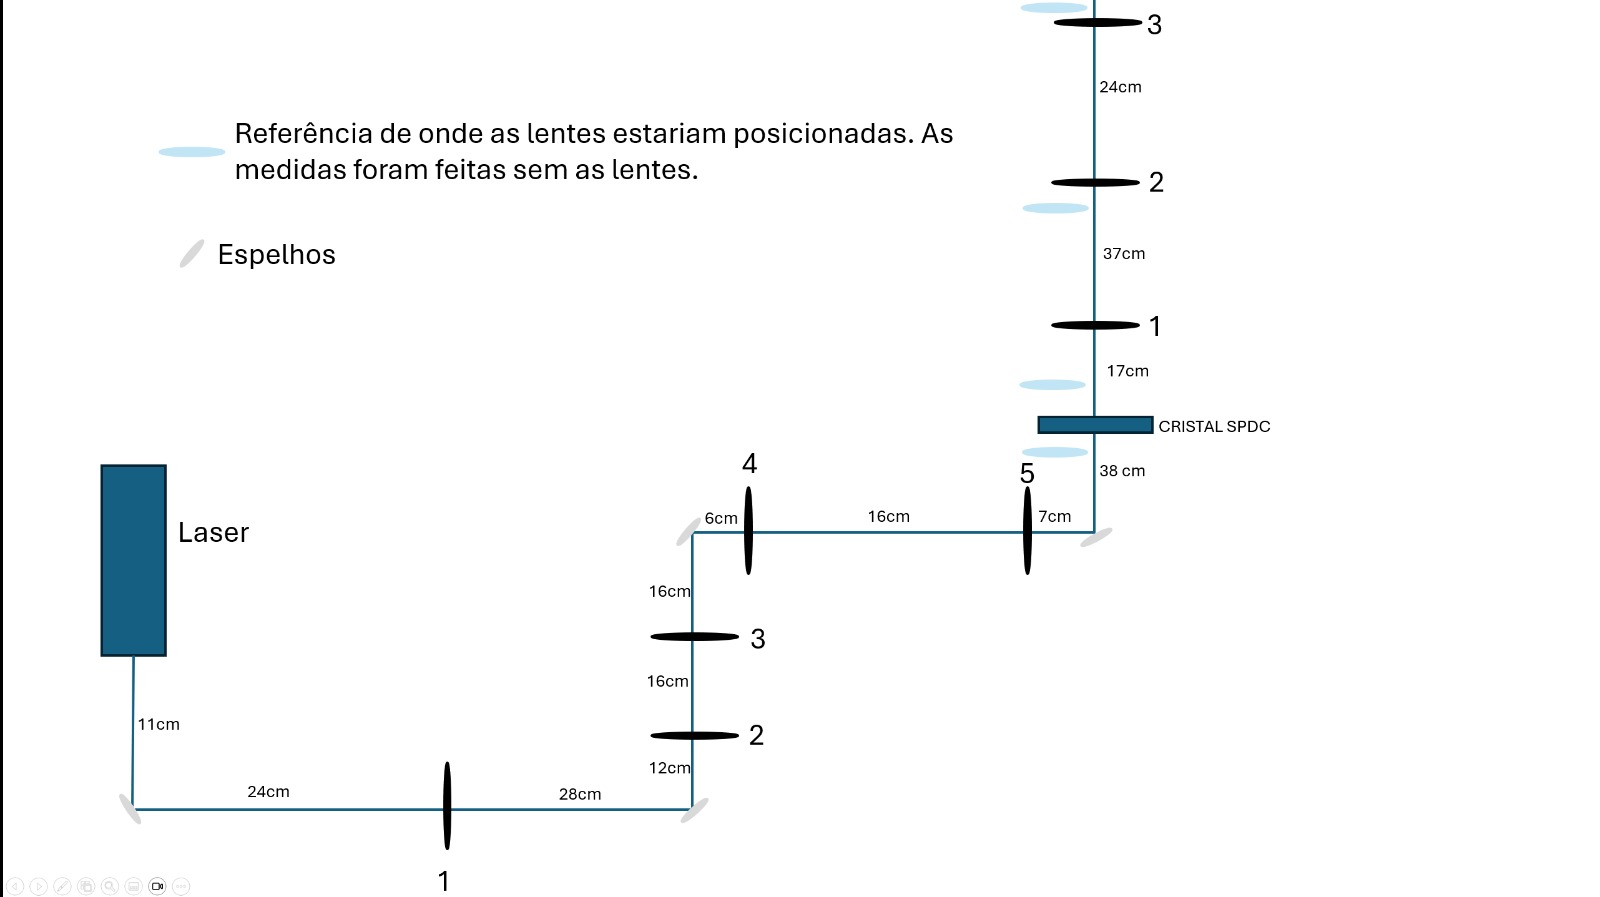


In [541]:
11+24+28+12+16+16+6+16+7+38-25### Distância do laser até a lente

149

In [542]:
### Apartir da imagem acima:
z_livre = np.array([0, 40, 56, 78, 94])*1e-2 + (35e-2) # metros

In [543]:
livre1 = pd.read_csv("Data/Data-1-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre2 = pd.read_csv("Data/Data-2-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre3 = pd.read_csv("Data/Data-3-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre4 = pd.read_csv("Data/Data-4-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre5 = pd.read_csv("Data/Data-5-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")

In [544]:
### Exemplo dos dados:
livre1.head()

,Measurement,Time [hh:mm:ss:zzz],Peak Position X[µm],Peak Position Y[µm],Centroid Position X[µm],Centroid Position Y[µm],AD Saturation[%],Total Power[dBm],Beam Width Clip X[µm],Beam Width Clip Y[µm],Gaussian Intensity X[%],Gaussian Intensity Y[%],Gaussian Diameter X[µm],Gaussian Diameter Y[µm],Unnamed: 14
0,1,10:40:10.100,-208.61,-134.92,-183.44,-92.26,67.68,20.85,750.96,914.65,95.53,95.47,793.63,936.24,NaN
1,2,10:40:20.075,-180.28,-189.23,-184.35,-104.05,72.93,21.06,780.74,863.09,95.82,95.25,784.58,936.61,NaN
2,3,10:40:30.081,-149.59,-111.31,-176.06,-99.74,68.30,20.97,740.69,912.77,95.77,95.45,765.84,938.80,NaN
3,4,10:40:40.081,-227.50,-98.33,-184.74,-97.63,66.32,20.91,751.36,917.23,95.81,95.35,774.97,955.89,NaN
4,5,10:40:50.081,-182.12,-130.20,-170.01,-92.97,69.85,20.92,761.04,879.89,95.81,95.38,778.47,952.20,NaN


In [545]:
files = [livre1, livre2, livre3, livre4, livre5]


def beam_waist(files):
    wX, wY = [],[]
    std_wX, std_wY = [], []
    if len(files )>1:
        for df in files:
            rx = df['Gaussian Diameter X[µm]']/2
            ry = df['Gaussian Diameter Y[µm]']/2
            
            wX.append(rx.mean()) 
            wY.append(ry.mean()) 
            std_wX.append(rx.std()) 
            std_wY.append(ry.std()) 
        wX = np.array(wX)
        wY = np.array(wY)
        std_wY = np.array(std_wY)
        std_wX = np.array(std_wX)        
    return wX, wY,std_wY,std_wX


w_X, w_Y,std_wY,std_wX = beam_waist(files)

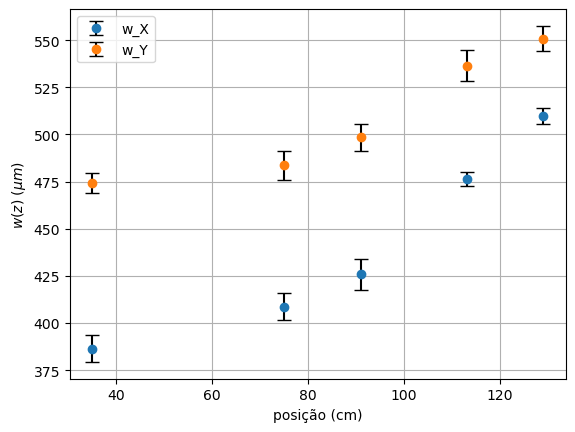

In [546]:
### Vamos plotar um exemplo:
plt.errorbar(z_livre*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_livre*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Agora vamos definir uma função que será usada nas outras caracterizações também. Essa função servirá para ajustar os nossos dados, com base na suposição que os feixes são gaussianos. A partir dessa suposição e do ajuste seremos capazes de encontrar os parâmetros desejados.

A teoria nos diz que a cintura do feixe se propaga no eixo $z$ descrito pela equação

$$
w(z) = w_0 \sqrt{1 + (\frac{z - z_0}{z_R})^2}
$$

Em que,
* $w_0$: cintura do feixe no mínimo;
* $z_0$: posição do $w_0$ (medido a partir da saída do laser);
* $z_R$: comprimento de Rayleigh;

Sendo assim faremos um ajuste de 3 parâmetros: $w_0$, $z_0$ e $z_R$. Poderemos também definir a divergência de nosso feixe:

$$
\theta = \frac{w_0}{z_R}
$$

Tendo obtido esses dados poderemos verificar a qualidade de nosso feixe, grandeza que será importante para os próximos ajustes realizados. Essa grandeza é o $M^2$, construimos ela considerando que existe um feixe gaussiano ideal (a partir da toeria de feixes gaussianos) e comparamos os resultados obtidos.

$$
M^2 = \frac{\pi w_0^2}{\lambda z_R}
$$

Embora não seja ideal ajustar três parâmetros ao mesmo tempo, vamos fazer isso para evitar de restrigir os valores obtidos de acordo com a teoria de feixes gaussianos ideais. Acredito que o ajuste não será tão prejudicado por isso, já que as medições foram bem distribuídas.

**Dúvida: O cálculo da divergência é feito usando uma fórmula baseada na ideia de que z>>$z_r$ e o termo na equação de W(z) pode ser negligenciado. Isso não me parece valer aqui.**

In [547]:
def gaussian_beam(z, w0, z0, zR, wavelength=325e-9, M2=None):
    if M2 is not None:
        zR = np.pi * w0**2 / (wavelength * M2)

    return w0 * np.sqrt(1 + ((z - z0) / zR)**2)
def gaussian_fit(w_X, w_Y, std_wX, std_wY, z,
                 wavelength=325e-9, M2_X=None, M2_Y=None,
                 p0_X=None, p0_Y=None):

    wx = np.array(w_X) * 1e-6
    wy = np.array(w_Y) * 1e-6

    sx = None if std_wX is None else np.array(std_wX) * 1e-6
    sy = None if std_wY is None else np.array(std_wY) * 1e-6

    # Fit each axis
    def fit_axis(w, sigma, M2, p0_user):

        if M2 is None:
            # Fit w0, z0 and zR freely
            def model(z, w0, z0, zR):
                return gaussian_beam(z, w0, z0, zR, wavelength)

            # User-defined initial guesses or defaults
            p0 = p0_user if p0_user is not None else [w.min(), -0.05, 2.0]

            bounds = (
                [1e-9, -np.inf, 1e-6],
                [np.inf, np.inf, np.inf]
            )

        else:
            # zR is restricted by M2 inside gaussian_beam
            def model(z, w0, z0):
                return gaussian_beam(z, w0, z0, None, wavelength, M2)

            # User-defined initial guesses or defaults
            p0 = p0_user if p0_user is not None else [w.min(), -0.05]

            bounds = (
                [1e-9, -np.inf],
                [np.inf, np.inf]
            )

        popt, pcov = curve_fit(
            model, z, w,
            p0=p0,
            bounds=bounds,
            sigma=sigma,
            absolute_sigma=(sigma is not None),
            maxfev=20000
        )

        if M2 is None:
            w0, z0, zR = popt
        else:
            w0, z0 = popt
            zR = np.pi * w0**2 / (wavelength * M2)

        return w0, z0, zR

    # Fit X and Y
    w0_X, z0_X, zR_X = fit_axis(wx, sx, M2_X, p0_X)
    w0_Y, z0_Y, zR_Y = fit_axis(wy, sy, M2_Y, p0_Y)

    # Divergence (in radians)
    divergence_X = w0_X / zR_X
    divergence_Y = w0_Y / zR_Y

    # Convert to milliradians
    divergence_X_mrad = divergence_X * 1000
    divergence_Y_mrad = divergence_Y * 1000

    # M²
    M2_X = np.pi * w0_X**2 / (wavelength * zR_X)
    M2_Y = np.pi * w0_Y**2 / (wavelength * zR_Y)

    return (w0_X, w0_Y, z0_X, z0_Y, zR_X, zR_Y,
            divergence_X_mrad, divergence_Y_mrad, M2_X, M2_Y)

Direção X:
  Raio da cintura w0 = 385.77 µm
  Posição da cintura z0 = 387.991 mm
  Comprimento de Rayleigh zR = 1037.343 mm
M^2 = 1.00
  Divergência = 0.372 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 473.21 µm
  Posição da cintura z0 = 421.761 mm
  Comprimento de Rayleigh zR = 1427.071 mm
M^2 = 1.00
  Divergência = 0.332 mrad (0.0157°)


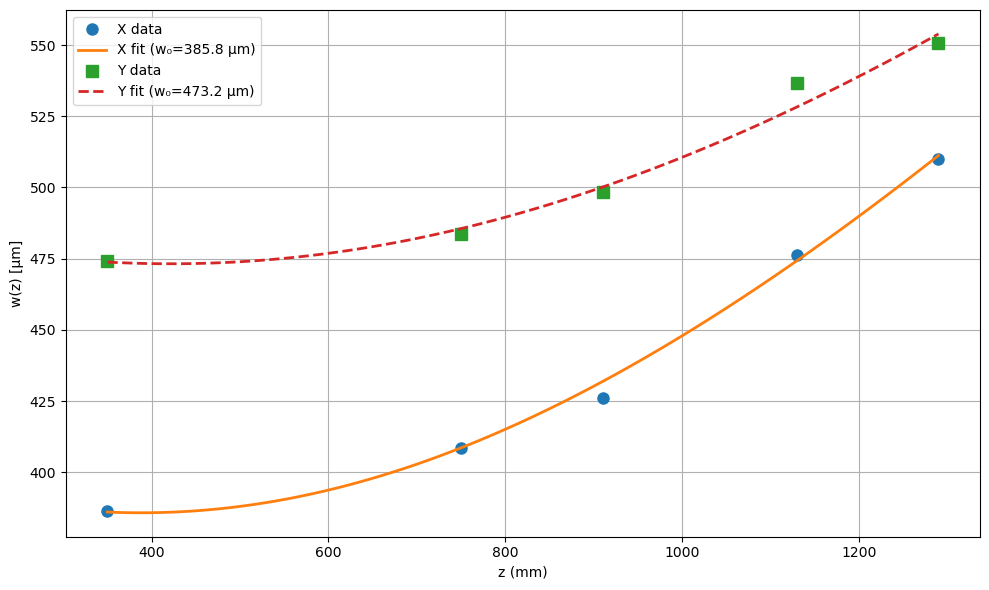

In [548]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_Xp,M2_Yp = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_livre)

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"M^2 = {M2_X:.2f}")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"M^2 = {M2_Y:.2f}")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_livre.min(), z_livre.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_livre*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_livre*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Parâmetros do feixe Gaussiano

| Parâmetro | Direção X | Direção Y |
|---|---:|---:|
| Raio da cintura ($w_0$) | 385.77 µm | 473.21 µm |
| Posição da cintura ($z_0$) | 38.8 cm | 42.2 cm |
| Comprimento de Rayleigh ($z_R$) | 1.04 m | 1.43 m |
| Divergência ($\theta$) | 0.372 mrad | 0.332 mrad |
| Divergência (°) | 0.0213° | 0.0190° |
| $M^2$ | 1.39 | 1.52 |

Embora a grande maioria dos parâmetros tenham valores razoáveis, de acordo com o spec-sheet a divergência ideal seria 0.11mrad . Porém, ainda está no limite (0.5mrad).

## Parâmetros Feixe Bombeio

Agora vamos verificar como ficam os parâmetros após o feixe passar pela lente de bombeio $f = 250$mm. Abaixo uma imagem que ilustra o setup das medidas.


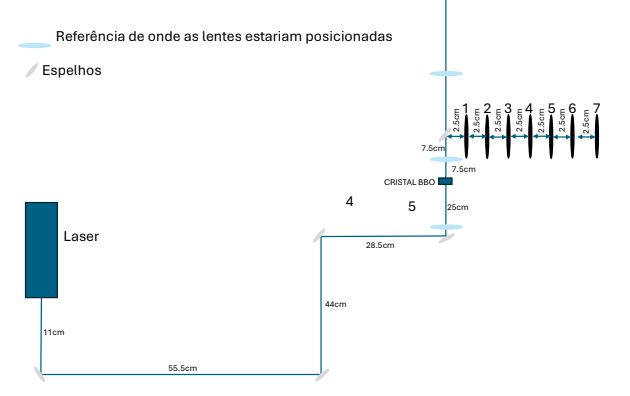

In [549]:
z_pos = np.array([i*2.5*1e-2 for i in range(0,7) ]) +(25+15+ 2.5)*1e-2

In [550]:
coleta1 = pd.read_csv("Data_2110_325/M1_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta2 = pd.read_csv("Data_2110_325/M2_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta3 = pd.read_csv("Data_2110_325/M3_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta4 = pd.read_csv("Data_2110_325/M4_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta5 = pd.read_csv("Data_2110_325/M5_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta6 = pd.read_csv("Data_2110_325/M6_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta7 = pd.read_csv("Data_2110_325/M7_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")

In [551]:
coleta1.head()

,Measurement,Time [hh:mm:ss:zzz],Peak Position X[µm],Peak Position Y[µm],Centroid Position X[µm],Centroid Position Y[µm],AD Saturation[%],Total Power[dBm],Beam Width Clip X[µm],Beam Width Clip Y[µm],Gaussian Intensity X[%],Gaussian Intensity Y[%],Gaussian Diameter X[µm],Gaussian Diameter Y[µm],Unnamed: 14
0,1,13:51:00.629,-187.36,-133.74,-220.38,-159.62,62.79,-0.09,803.82,875.79,95.54,94.97,856.44,933.28,NaN
1,2,13:51:01.610,-164.93,-170.34,-233.94,-155.26,61.92,0.09,819.95,898.32,95.63,95.35,874.33,937.07,NaN
2,3,13:51:02.609,-157.85,-97.38,-229.44,-136.67,59.42,-0.05,796.38,907.41,95.71,95.21,845.47,935.32,NaN
3,4,13:51:03.610,-205.07,-175.06,-226.56,-143.36,61.26,-0.02,775.65,854.20,95.66,95.10,833.10,932.72,NaN
4,5,13:51:04.611,-147.23,-169.57,-228.55,-149.98,62.51,0.05,791.52,883.61,95.53,94.93,836.28,932.69,NaN


In [552]:
files = [coleta1, coleta2, coleta3, coleta4, coleta5, coleta6, coleta7]

w_X, w_Y,std_wY,std_wX = beam_waist(files)

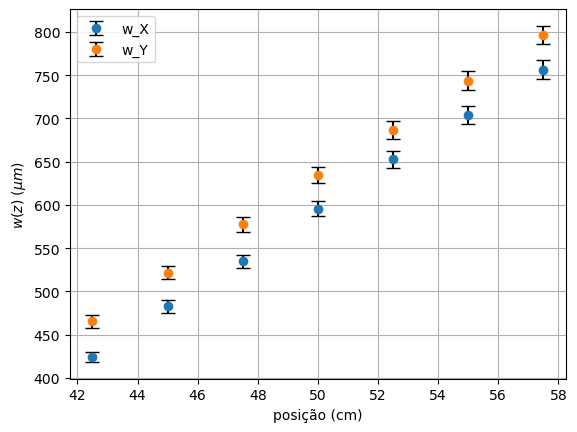

In [553]:
### Vamos plotar um exemplo:
plt.errorbar(z_pos*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_pos*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

In [554]:
M2_Yp

1.5168027682108116

Direção X:
  Raio da cintura w0 = 63.79 µm
  Posição da cintura z0 = 237.927 mm
  Comprimento de Rayleigh zR = 28.364 mm
  Divergência = 2.249 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 70.48 µm
  Posição da cintura z0 = 217.862 mm
  Comprimento de Rayleigh zR = 31.654 mm
  Divergência = 2.226 mrad (0.0157°)


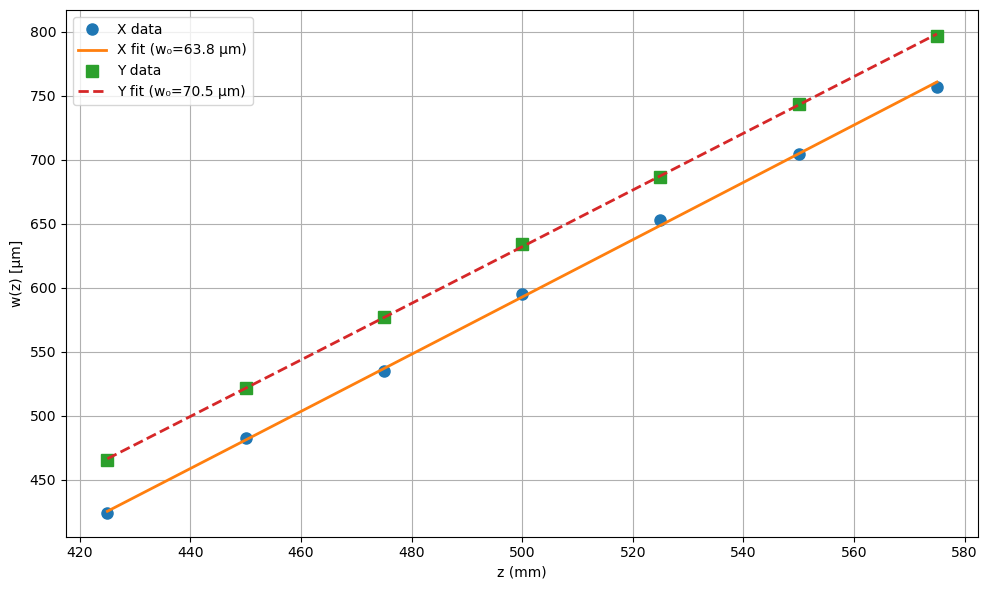

In [555]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_X,M2_Y = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_pos,M2_X = M2_Xp, M2_Y = M2_Yp )

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_pos.min(), z_pos.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_pos*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_pos*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [556]:
razao_x = zR_X/2e-3
razao_y = zR_Y/2e-3
print(razao_x, razao_y)

14.18196371530889 15.827135292481541


### Parâmetros do Feixe Gaussiano após lente de bombeio:


| Parâmetro | Direção X | Direção Y |
|---|---:|---:|
| Raio da cintura ($w_0$) | 63.79 µm | 70.48 µm |
| Posição da cintura ($z_0$) | 237.927 mm | 217.862 mm |
| Comprimento de Rayleigh ($z_R$) | 28.364 mm | 31.654 mm |
| Divergência ($\theta$) | 2.249 mrad | 2.226 mrad |
| Divergência (°) | 0.1289° | 0.1275° |


Ou seja, note que nosso cristal não está na cintura do feixe! Podemos calcular a cintura do feixe na distância focal da lente. 

A partir de agora as imagens foram geradas por mim usando o ChatGPT.

In [557]:
print(f'Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo X: {gaussian_beam(250e-3, w0_X,z0_X,zR_X)*1e6:.2f}µm') 
print(f'Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo Y: {gaussian_beam(250e-3, w0_Y,z0_Y,zR_Y)*1e6:.2f}µm') 

Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo X: 69.33µm
Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo Y: 100.43µm


Esse resultado NÃO é compatível com o valor medido hoje pelo Thiago. Ele mediu uma cintura de X: $44,59 \mu m$ e Y: $43.825 \mu m $

A distância em ambos os casos (X, Y) da cintura ao cristal é de 13cm e 33cm.

--------
Dúvida: os dados crescem linearmente, eu suponho que seja, porque estamos pegando um trecho muito pequeno dessa curva que descreve o feixe, afinal uma parabola se vista de muito perto é uma reta, por exemplo. Isso talvez possa afetar nosso ajuste.

## Definição dos parâmetros para o feixe contra-propagante

Vamos fazer o mesmo para o feixe contra-propagante. Esse feixe passa por algumas lentes:
* Lente asférica: $f = 11$mm
* Telescópio: $f_2 = 200$mm e $f_1 = 250$mm
* Lente de coleta: $f_C = 75$mm

A representação do setup está abaixo:


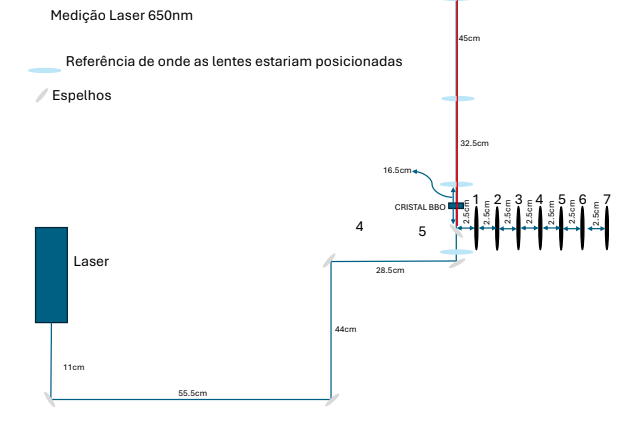

In [558]:
contra1 = pd.read_csv("Data_2110_650/M1_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra2 = pd.read_csv("Data_2110_650/M2_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra3 = pd.read_csv("Data_2110_650/M3_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra4 = pd.read_csv("Data_2110_650/M4_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra5 = pd.read_csv("Data_2110_650/M5_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra6 = pd.read_csv("Data_2110_650/M6_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra0 = pd.read_csv("Data_2110_650/M7_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
# 7 foi descartado porque deu problema na medicao do diametro

In [559]:
z_contra = np.array([5.6, 7.5,10,13.3,15.,17.3,19.8 ])*1e-2 +  4e-2

In [560]:
contra2.head()

,Measurement,Time [hh:mm:ss:zzz],Peak Position X[µm],Peak Position Y[µm],Centroid Position X[µm],Centroid Position Y[µm],AD Saturation[%],Total Power[dBm],Beam Width Clip X[µm],Beam Width Clip Y[µm],Gaussian Intensity X[%],Gaussian Intensity Y[%],Gaussian Diameter X[µm],Gaussian Diameter Y[µm],Unnamed: 14
0,1,15:58:13.502,-161.39,443.87,-43.99,99.35,78.84,8.43,2526.19,2533.96,93.06,93.12,2567.78,2556.58,NaN
1,2,15:58:14.477,-165.98,449.44,-44.30,99.91,78.69,8.43,2518.09,2537.17,93.00,93.07,2573.38,2556.10,NaN
2,3,15:58:15.483,-162.57,444.72,-43.71,99.89,78.56,8.42,2519.11,2531.68,92.99,93.10,2572.25,2551.84,NaN
3,4,15:58:16.476,-161.39,444.72,-44.22,100.02,78.60,8.43,2524.12,2530.94,93.08,93.09,2568.78,2555.03,NaN
4,5,15:58:17.474,-157.85,439.26,-43.90,99.51,78.41,8.43,2518.26,2545.77,93.03,93.09,2566.90,2554.29,NaN


In [561]:
files = [contra0, contra1, contra2, contra3, contra4, contra5, contra6]

w_X, w_Y, std_wY, std_wX = beam_waist(files)


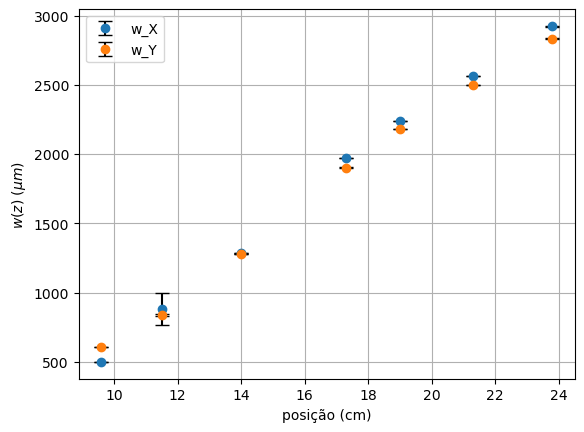

In [562]:
# Vamos plotar um exemplo:
plt.errorbar(z_contra*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_contra*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Direção X:
  Raio da cintura w0 = 11.65 µm
  Posição da cintura z0 = 67.838 mm
  Comprimento de Rayleigh zR = 0.656 mm
M^2 = 1.00
  Divergência = 17.754 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 12.80 µm
  Posição da cintura z0 = 58.616 mm
  Comprimento de Rayleigh zR = 0.791 mm
M^2 = 1.00
  Divergência = 16.169 mrad (0.0157°)


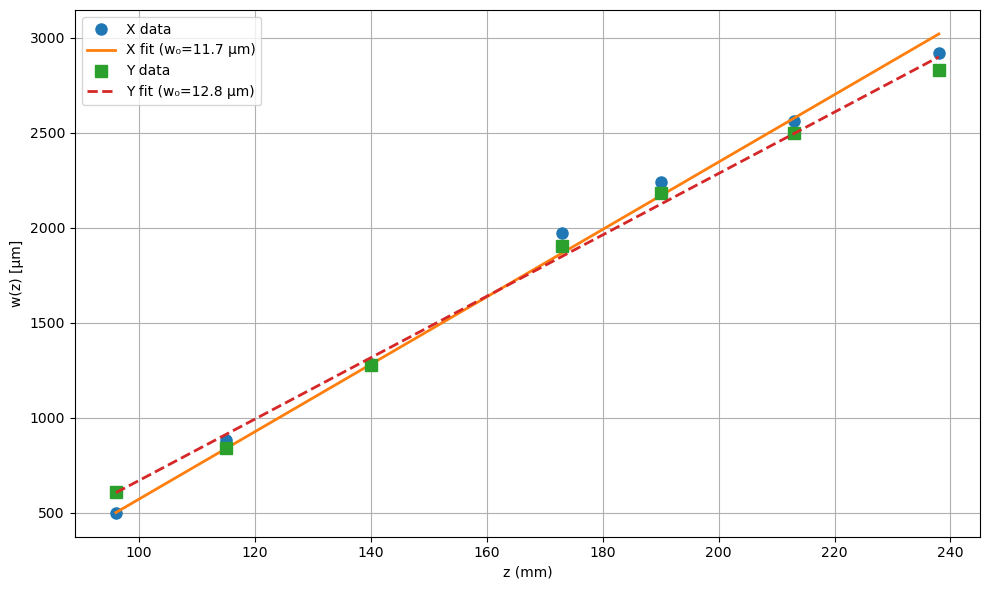

In [537]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_X,M2_Y = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_contra,wavelength = 650e-9, M2_X = 1, M2_Y = 1)

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"M^2 = {M2_X:.2f}")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"M^2 = {M2_Y:.2f}")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_contra.min(), z_contra.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_contra*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_contra*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [538]:
razao_x = zR_X/2e-3
razao_y = zR_Y/2e-3
print(razao_x, razao_y)

0.328189292309212 0.39570196645242683


### Parâmetros do feixe Gaussiano contra-propagante:

| Parâmetro | Direção X | Direção Y |
|---|---:|---:|
| Raio da cintura ($w_0$) | 5.74 µm | 6.44 µm |
| Posição da cintura ($z_0$) | 68.197 mm | 58.173 mm |
| Comprimento de Rayleigh ($z_R$) | 0.319 mm | 0.401 mm |
| Divergência ($\theta$) | 18.011 mrad | 16.071 mrad |
| Divergência (°) | 1.032° | 0.921° |

Tive que impor na função que $M^2 = 1$ para garantir que houvesse uma restrição em $z_R$ e o ajuste convergisse para valores mais realistas. Os valores nos mostram que a cintura do feixe contra-propagante está anterior ao cristal em $7$mm no eixo X e em $17$mm no eixo Y. 

### Feixe contrapropagante livre:


Precisamos de medidas para o feixe vermelho se propagando livremente.

### Segunda tentativa com o propagante após a lente

Vamos refazer as medições pegando também a própria cintura do f

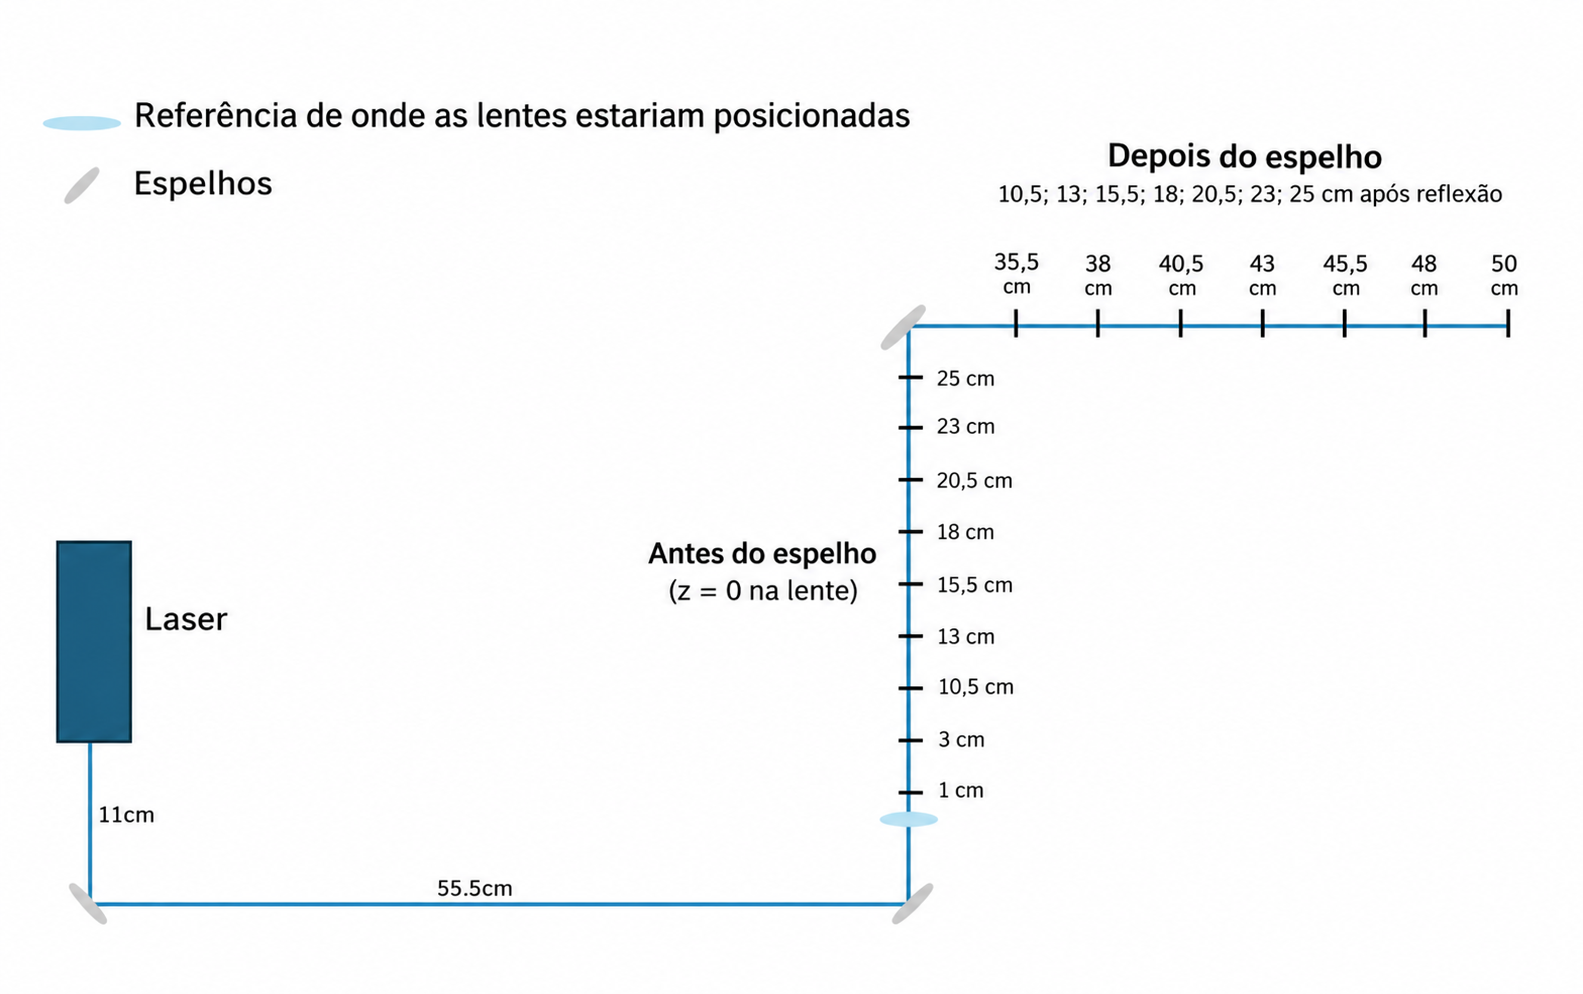

In [586]:
z_325_antes = np.array([1,3,10.5,13,15.5,18,20.5,23,25])*1e-2 
z_325_depois = 25e-2 + np.array([10.5,13,15.5,18,20.5,23,25])*1e-2
z_325 = np.concatenate((z_325_antes,z_325_depois))

In [587]:
z_325

array([0.01 , 0.03 , 0.105, 0.13 , 0.155, 0.18 , 0.205, 0.23 , 0.25 ,
       0.355, 0.38 , 0.405, 0.43 , 0.455, 0.48 , 0.5  ])

In [588]:
### Antes da lente:
l325_1 = pd.read_csv("Data_2310_325/M9_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_2 = pd.read_csv("Data_2310_325/M8_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_3 = pd.read_csv("Data_2310_325/M1_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_4 = pd.read_csv("Data_2310_325/M2_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_5 = pd.read_csv("Data_2310_325/M3_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_6 = pd.read_csv("Data_2310_325/M4_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_7 = pd.read_csv("Data_2310_325/M5_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_8 = pd.read_csv("Data_2310_325/M6_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_9 = pd.read_csv("Data_2310_325/M7_#001.txt", sep="\t",skiprows=10,encoding="latin1")

### Depois da lente:
l325_10 = pd.read_csv("Data_2310_325/M10_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_11 = pd.read_csv("Data_2310_325/M11_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_12 = pd.read_csv("Data_2310_325/M12_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_13 = pd.read_csv("Data_2310_325/M13_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_14 = pd.read_csv("Data_2310_325/M14_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_15 = pd.read_csv("Data_2310_325/M15_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_16 = pd.read_csv("Data_2310_325/M16_#001.txt", sep="\t",skiprows=10,encoding="latin1")

In [589]:
files = [l325_1,l325_2, l325_3, l325_4, l325_5, l325_6, l325_7,l325_8,l325_9,l325_10, l325_11, l325_12, l325_13, l325_14,l325_15,l325_16]
w_X, w_Y,std_wY,std_wX = beam_waist(files)

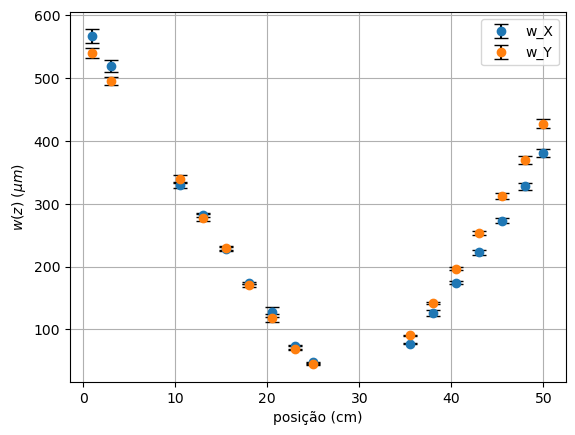

In [590]:
# Vamos plotar um exemplo:
plt.errorbar(z_325*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_325*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Direção X:
  Raio da cintura w0 = 88.38 µm
  Posição da cintura z0 = 282.446 mm
  Comprimento de Rayleigh zR = 54.452 mm
  Divergência = 1.623 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 91.46 µm
  Posição da cintura z0 = 273.966 mm
  Comprimento de Rayleigh zR = 53.310 mm
  Divergência = 1.716 mrad (0.0157°)


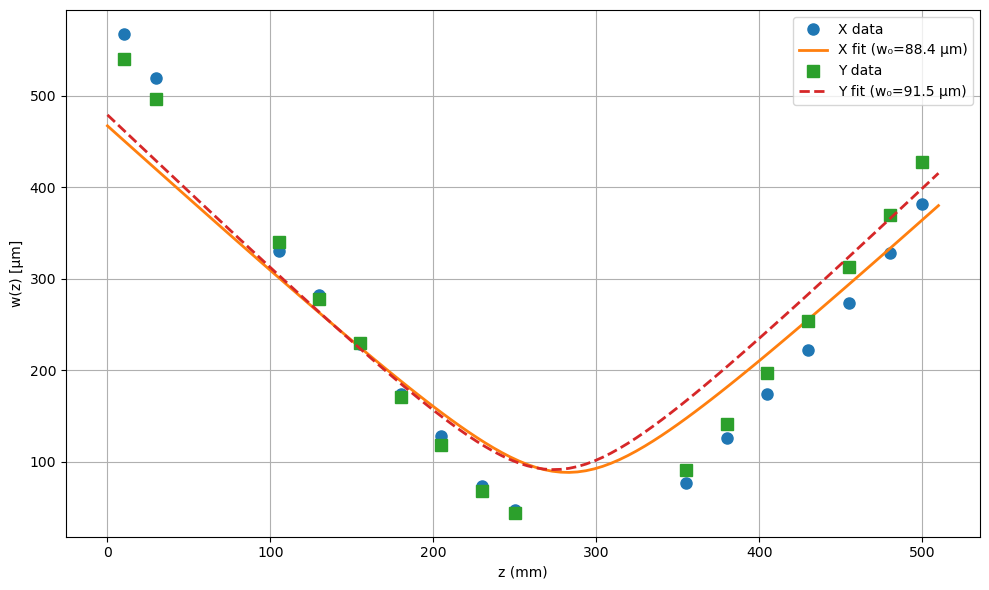

In [591]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_X,M2_Y = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_325,M2_X = M2_Xp, M2_Y = M2_Yp
                                                                                          )

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_325.min() - 1e-2, z_325.max() +1e-2, 100)
plt.figure(figsize=(10, 6))
plt.plot(z_325*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_325*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [569]:
razao_x = zR_X/2e-3
razao_y = zR_Y/2e-3
print(razao_x, razao_y)

13.180920977991502 12.86376065212623


O ajuste está péssimo e incompatível com os anteriores.

In [605]:
import numpy as np

# ============================================================
# FUNÇÕES: MATRIZES ABCD
# ============================================================

def propagation(d):
    """Matriz de propagação livre por uma distância d [m]."""
    return np.array([
        [1.0, d],
        [0.0, 1.0]
    ])


def lens(f):
    """Matriz de lente fina de distância focal f [m]."""
    return np.array([
        [1.0, 0.0],
        [-1.0/f, 1.0]
    ])


def transform_q(M, q):
    """Transformação ABCD do parâmetro complexo q."""
    A, B = M[0]
    C, D = M[1]

    return (A*q + B)/(C*q + D)


# ============================================================
# PARÂMETROS INICIAIS DO FEIXE CONTRA-PROPAGANTE
# ============================================================

wavelength = 650e-9       # Comprimento de onda [m]
MFD = 4.5e-6              # Mode Field Diameter da fibra [m]
w0 = MFD / 2              # Raio da cintura na fibra [m]

M2 = 1.0                  # Fator de qualidade do feixe
L = 2e-3                  # Comprimento do cristal [m]


# ============================================================
# PARÂMETROS DO SISTEMA ÓPTICO
# ============================================================

# Fibra -> lente asférica
d0 = 11e-3
fa = 11e-3

# Lente asférica -> telescópio
d1 = 211e-3

# Telescópio (primeira lente)
f2 = 200e-3

# Distância entre as lentes do telescópio
d2 = 450e-3

# Telescópio (segunda lente)
f1 = 250e-3

# Telescópio -> lente de coleta
d3 = 325e-3

# Lente de coleta
fC = 75e-3


# ============================================================
# PARÂMETRO COMPLEXO INICIAL
# ============================================================

# Comprimento de Rayleigh efetivo na fibra
zR_initial = np.pi * w0**2 / (M2 * wavelength)

# Consideramos a cintura na saída da fibra
q0 = 1j * zR_initial


# ============================================================
# MATRIZ ABCD TOTAL
# ============================================================

# A ordem das operações é da direita para a esquerda.

M_total = (
    lens(fC)
    @ propagation(d3)
    @ lens(f1)
    @ propagation(d2)
    @ lens(f2)
    @ propagation(d1)
    @ lens(fa)
    @ propagation(d0)
)


# Parâmetro imediatamente após a lente de coleta
q_final = transform_q(M_total, q0)

# Comprimento de Rayleigh após a lente de coleta
zR_C = np.imag(q_final)

# Raio da nova cintura
w0_C = np.sqrt(M2 * wavelength * zR_C / np.pi)

# Razão de interesse
N_C = zR_C / L


print("Sistema de coleta - Matrizes ABCD")

print(f"\nComprimento de onda: {wavelength*1e9:.1f} nm")
print(f"MFD da fibra: {MFD*1e6:.2f} µm")
print(f"M²: {M2:.2f}")
print(f"Comprimento do cristal: {L*1e3:.2f} mm")

print("\n--- FEIXE INICIAL ---")
print(f"Cintura inicial: {w0*1e6:.3f} µm")
print(f"Rayleigh inicial: {zR_initial*1e6:.3f} µm")

print("\n--- FEIXE APÓS A LENTE DE COLETA ---")
print(f"Rayleigh final: {zR_C*1e3:.4f} mm")
print(f"Cintura final: {w0_C*1e6:.4f} µm")

print("\n--- RAZÃO DE INTERESSE ---")
print(f"zR_C / L = {N_C:.6f}")

print("\n--- VERIFICAÇÃO DA MATRIZ ---")
print(f"Determinante ABCD: {np.linalg.det(M_total):.6f}")



Sistema de coleta - Matrizes ABCD

Comprimento de onda: 650.0 nm
MFD da fibra: 4.50 µm
M²: 1.00
Comprimento do cristal: 2.00 mm

--- FEIXE INICIAL ---
Cintura inicial: 2.250 µm
Rayleigh inicial: 24.468 µm

--- FEIXE APÓS A LENTE DE COLETA ---
Rayleigh final: 0.7280 mm
Cintura final: 12.2727 µm

--- RAZÃO DE INTERESSE ---
zR_C / L = 0.363989

--- VERIFICAÇÃO DA MATRIZ ---
Determinante ABCD: 1.000000
